# Smart и Ultra. Какой тариф приносил больше выручки

Учебный проект Яндекс Практикума · «Мегалайн» · 2018 год

Коммерческий отдел выбирает, какой тариф продвигать. Я посчитаю, сколько оператор получал за месяц в среднем от одного абонента и сколько в сумме принесли пользователи каждого тарифа в выборке. Для этого соберу помесячные начисления из звонков, сообщений и интернет-сессий, а затем проверю различия между тарифами и регионами.

**Короткий ответ.** Месяц с зарегистрированной активностью приносил в среднем 2 070 ₽ на Ultra и 1 290 ₽ на Smart. Но в выборке у Smart оказалось больше абонентов и больше суммарная выручка. Чтобы распределить рекламный бюджет, понадобятся также стоимость привлечения и срок удержания новых клиентов.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats as st

colors = {'smart': '#16756d', 'ultra': '#a65136'}
plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'figure.dpi': 95,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#afbfbe',
    'axes.titlelocation': 'left', 'axes.titleweight': 'bold', 'axes.axisbelow': True,
    'font.size': 10, 'axes.prop_cycle': plt.cycler(color=list(colors.values())),
    'grid.alpha': 0.25,
})

## 1. Знакомство с данными

За 2018 год оператор собрал три журнала событий — звонки, интернет-сессии и сообщения. По `user_id` каждую запись можно связать с абонентом, а по названию тарифа — найти условия оплаты.

Пять исходных CSV можно положить рядом с ноутбуком или в подпапку `data` либо `datasets`. В тренажёре используется `/datasets`. Другую папку можно задать переменной окружения `MEGALINE_DATA_DIR`.

При локальном запуске можно посмотреть первые строки журналов, карточки абонентов и примеры их месячного потребления. В публичной версии сохранены сводные таблицы и графики.

In [2]:
files = ['calls.csv', 'internet.csv', 'messages.csv', 'tariffs.csv', 'users.csv']
custom_dir = os.environ.get('MEGALINE_DATA_DIR')
folders = ([Path(custom_dir).expanduser()] if custom_dir else
           [Path('.'), Path('data'), Path('datasets'), Path('/datasets')])
data_dir = next((folder for folder in folders
                 if all((folder / name).is_file() for name in files)), None)
if data_dir is None:
    raise FileNotFoundError('Для запуска нужны пять файлов CSV в одной папке. '
                            'Укажите её в MEGALINE_DATA_DIR.')

### Звонки · задания 1–4

In [3]:
# Задание 1. Загрузка журнала звонков
calls = pd.read_csv(data_dir / 'calls.csv')

In [4]:
# Задание 2. Первые пять звонков
calls.head()

In [5]:
# Задание 3. Структура журнала звонков
calls.info()

<class 'pandas.DataFrame'>
RangeIndex: 202607 entries, 0 to 202606
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   id         202607 non-null  str    
 1   call_date  202607 non-null  str    
 2   duration   202607 non-null  float64
 3   user_id    202607 non-null  int64  
dtypes: float64(1), int64(1), str(2)
memory usage: 6.2 MB


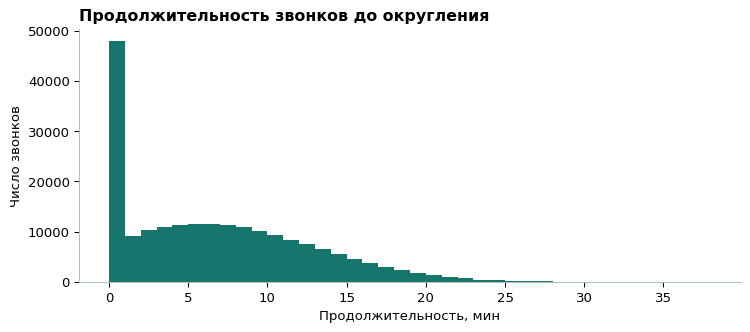

In [6]:
# Задание 4. Распределение продолжительности звонков
ax = calls['duration'].hist(bins=38, figsize=(8, 3.6), grid=False)
ax.set(title='Продолжительность звонков до округления',
       xlabel='Продолжительность, мин', ylabel='Число звонков')
plt.tight_layout()
plt.show()

У 39 613 звонков длительность равна нулю. Это пропущенные вызовы. Среди состоявшихся разговоров медианная длительность — 7,74 минуты, самый длинный продолжался 38 минут.

### Интернет-сессии · задания 5–8

In [7]:
# Задание 5. Загрузка журнала интернет-сессий
sessions = pd.read_csv(data_dir / 'internet.csv')

In [8]:
# Задание 6. Первые пять сессий
sessions.head()

In [9]:
# Задание 7. Структура журнала интернет-сессий
sessions.info()

<class 'pandas.DataFrame'>
RangeIndex: 149396 entries, 0 to 149395
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Unnamed: 0    149396 non-null  int64  
 1   id            149396 non-null  str    
 2   mb_used       149396 non-null  float64
 3   session_date  149396 non-null  str    
 4   user_id       149396 non-null  int64  
dtypes: float64(1), int64(2), str(2)
memory usage: 5.7 MB


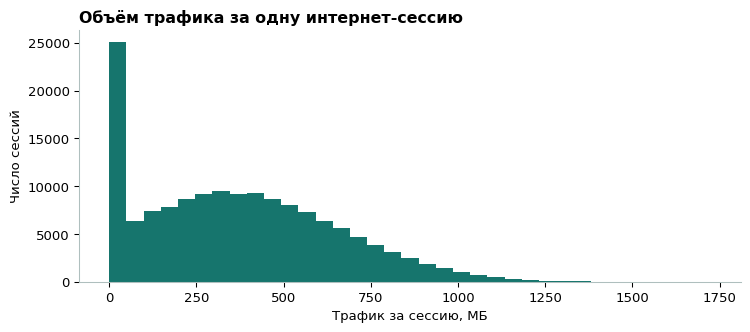

In [10]:
# Задание 8. Распределение объёма трафика
ax = sessions['mb_used'].hist(bins=35, figsize=(8, 3.6), grid=False)
ax.set(title='Объём трафика за одну интернет-сессию',
       xlabel='Трафик за сессию, МБ', ylabel='Число сессий')
plt.tight_layout()
plt.show()

В 19 598 сессиях расход трафика равен нулю. У сессий с положительным расходом медиана составляет около 401 МБ.

### Сообщения · задания 9–11

In [11]:
# Задание 9. Загрузка журнала сообщений
messages = pd.read_csv(data_dir / 'messages.csv')

In [12]:
# Задание 10. Первые пять сообщений
messages.head()

In [13]:
# Задание 11. Структура журнала сообщений
messages.info()

<class 'pandas.DataFrame'>
RangeIndex: 123036 entries, 0 to 123035
Data columns (total 3 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   id            123036 non-null  str  
 1   message_date  123036 non-null  str  
 2   user_id       123036 non-null  int64
dtypes: int64(1), str(2)
memory usage: 2.8 MB


### Условия тарифов · задания 12–14

In [14]:
# Задание 12. Загрузка справочника тарифов
tariffs = pd.read_csv(data_dir / 'tariffs.csv')

In [15]:
# Задание 13. Все условия тарифных планов
tariffs

,messages_included,mb_per_month_included,minutes_included,rub_monthly_fee,rub_per_gb,rub_per_message,rub_per_minute,tariff_name
0,50,15360,500,550,200,3,3,smart
1,1000,30720,3000,1950,150,1,1,ultra


In [16]:
# Задание 14. Структура справочника тарифов
tariffs.info()

<class 'pandas.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   messages_included      2 non-null      int64
 1   mb_per_month_included  2 non-null      int64
 2   minutes_included       2 non-null      int64
 3   rub_monthly_fee        2 non-null      int64
 4   rub_per_gb             2 non-null      int64
 5   rub_per_message        2 non-null      int64
 6   rub_per_minute         2 non-null      int64
 7   tariff_name            2 non-null      str  
dtypes: int64(7), str(1)
memory usage: 260.0 bytes


### Абоненты · задания 15–17

In [17]:
# Задание 15. Загрузка сведений об абонентах
users = pd.read_csv(data_dir / 'users.csv')

In [18]:
# Задание 16. Первые пять абонентов
users.head()

In [19]:
# Задание 17. Структура таблицы абонентов
users.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   user_id     500 non-null    int64
 1   age         500 non-null    int64
 2   churn_date  38 non-null     str  
 3   city        500 non-null    str  
 4   first_name  500 non-null    str  
 5   last_name   500 non-null    str  
 6   reg_date    500 non-null    str  
 7   tariff      500 non-null    str  
dtypes: int64(2), str(6)
memory usage: 31.4 KB


У 38 из 500 абонентов заполнена дата прекращения обслуживания. У остальных 462 тариф действовал на момент выгрузки.

## 2. Подготовка данных

### Даты и единицы измерения · задания 18–23

Для расчёта оплаты округляем вверх продолжительность каждого звонка. Пропущенный вызов входит в количество звонков и добавляет ноль минут к расходу. Трафик отдельной сессии сохраняем в исходных мегабайтах, чтобы сначала сложить его за месяц.

In [20]:
# Задание 18. Преобразование дат
users['reg_date'] = pd.to_datetime(users['reg_date'], format='%Y-%m-%d')
users['churn_date'] = pd.to_datetime(users['churn_date'], format='%Y-%m-%d')
calls['call_date'] = pd.to_datetime(calls['call_date'], format='%Y-%m-%d')
messages['message_date'] = pd.to_datetime(messages['message_date'], format='%Y-%m-%d')
sessions['session_date'] = pd.to_datetime(sessions['session_date'], format='%Y-%m-%d')

In [21]:
# Задание 19. Округление длительности каждого звонка
calls['duration'] = np.ceil(calls['duration']).astype(int)

In [22]:
# Задание 20. Удаление сохранённого индекса CSV
sessions = sessions.drop(columns='Unnamed: 0', errors='ignore')

In [23]:
# Задание 21. Месяц звонка
calls['month'] = calls['call_date'].dt.month

In [24]:
# Задание 22. Месяц отправки сообщения
messages['month'] = messages['message_date'].dt.month

In [25]:
# Задание 23. Месяц интернет-сессии
sessions['month'] = sessions['session_date'].dt.month

### Использование услуг по месяцам · задания 24–27

В каждой таблице одна строка соответствует одному абоненту за один календарный месяц. Журнал услуги даёт строку только за те месяцы, в которых встречается хотя бы одно событие этой услуги.

In [26]:
# Задание 24. Число звонков
calls_per_month = calls.groupby(['user_id', 'month']).agg({'duration': 'count'})
calls_per_month.head(30)

In [27]:
# Задание 25. Минуты разговора
minutes_per_month = calls.groupby(['user_id', 'month']).agg(minutes=('duration', 'sum'))
minutes_per_month.head(30)

In [28]:
# Задание 26. Число отправленных сообщений
messages_per_month = messages.groupby(['user_id', 'month']).agg(messages=('message_date', 'count'))
messages_per_month.head(30)

In [29]:
# Задание 27. Суммарный объём трафика в мегабайтах
sessions_per_month = sessions.groupby(['user_id', 'month']).agg({'mb_used': 'sum'})

## 3. Потребление и помесячная выручка

За основу беру месяцы, в которых зарегистрирован хотя бы один звонок, сообщение или интернет-сессия. Если в таком месяце нет записей по одному виду услуг, его потребление равно нулю. Дата отключения остаётся пустой у тех, чей договор ещё действовал при выгрузке. Из таблицы клиентов для анализа нужны только идентификатор, город и тариф.

In [30]:
usage = pd.concat([
    calls_per_month.rename(columns={'duration': 'calls'}),
    minutes_per_month, messages_per_month, sessions_per_month,
], axis=1, join='outer').sort_index()
display(usage.isna().sum().rename('Пропуски после объединения').to_frame())
usage = usage.fillna(0).astype({'calls': int, 'minutes': int, 'messages': int})
user_behavior = (
    usage.reset_index()
    .merge(users[['user_id', 'city', 'tariff']], on='user_id', how='left',
           validate='many_to_one')
    .merge(tariffs.rename(columns={'tariff_name': 'tariff'}), on='tariff',
           how='left', validate='many_to_one')
)
assert not user_behavior.duplicated(['user_id', 'month']).any()
assert user_behavior[['city', 'tariff', 'rub_monthly_fee']].notna().all().all()
print(f"Клиенты с активностью: {user_behavior['user_id'].nunique()} из {len(users)}.")
print(f"Клиенто-месяцы с активностью: {len(user_behavior)}.")
print(f"Указана дата отключения: {users['churn_date'].notna().sum()} из {len(users)}.")

,Пропуски после объединения
calls,40
minutes,40
messages,497
mb_used,11


Клиенты с активностью: 498 из 500.
Клиенто-месяцы с активностью: 3214.
Указана дата отключения: 38 из 500.


### Из чего складывается счёт

Минуты уже округлены вверх отдельно для каждого звонка. Для интернета сначала суммирую весь месячный трафик в МБ, вычитаю пакет, а затем округляю вверх до целого платного ГБ. Например, превышение на 1 МБ оплачивается как 1 ГБ, на 1 025 МБ — как 2 ГБ. Абонентская плата начисляется целиком за каждый месяц в расчёте.

In [31]:
user_behavior['paid_minutes'] = (
    user_behavior['minutes'] - user_behavior['minutes_included']
).clip(lower=0)
user_behavior['paid_messages'] = (
    user_behavior['messages'] - user_behavior['messages_included']
).clip(lower=0)
user_behavior['paid_mb'] = (
    user_behavior['mb_used'] - user_behavior['mb_per_month_included']
).clip(lower=0)
user_behavior['paid_gb'] = np.ceil(user_behavior['paid_mb'] / 1024).astype(int)

user_behavior['cost_minutes'] = user_behavior['paid_minutes'] * user_behavior['rub_per_minute']
user_behavior['cost_messages'] = user_behavior['paid_messages'] * user_behavior['rub_per_message']
user_behavior['cost_gb'] = user_behavior['paid_gb'] * user_behavior['rub_per_gb']
extras = ['cost_minutes', 'cost_messages', 'cost_gb']
user_behavior['total_cost'] = user_behavior['rub_monthly_fee'] + user_behavior[extras].sum(axis=1)
assert user_behavior['total_cost'].ge(user_behavior['rub_monthly_fee']).all()

### Как пользовались услугами

Для каждого месяца и тарифа считаю среднее, медиану и выборочное стандартное отклонение. На графиках слева — среднее по абонентам этого месяца, справа — распределение по всем наблюдаемым месяцам каждого тарифа. У трафика здесь показан фактически переданный объём в ГБ.

In [32]:
user_behavior['gb_used'] = user_behavior['mb_used'] / 1024
fields = {'calls': 'Звонки, шт.', 'minutes': 'Разговоры, мин',
          'messages': 'Сообщения, шт.', 'gb_used': 'Интернет, ГБ'}
stats_df = user_behavior.groupby(['month', 'tariff'])[list(fields)].agg(['mean', 'std', 'median'])
display(stats_df.rename(columns=fields, level=0).rename(
    columns={'mean': 'Среднее', 'std': 'Ст. откл.', 'median': 'Медиана'}, level=1
).round(1))

Звонки, шт.                   Разговоры, мин                    \
                 Среднее Ст. откл. Медиана        Среднее Ст. откл. Медиана   
month tariff                                                                  
1     smart         27.7      20.8    20.5          203.9     154.2   162.5   
      ultra         59.4      41.6    51.0          428.1     269.8   382.0   
2     smart         40.2      25.4    38.5          298.7     190.8   258.0   
      ultra         41.5      41.0    25.0          297.1     296.5   168.0   
3     smart         54.3      25.5    59.0          390.1     191.9   409.0   
      ultra         67.7      44.8    57.0          489.6     333.7   403.0   
4     smart         51.3      25.7    52.0          367.1     186.5   368.5   
      ultra         64.1      36.3    61.0          458.0     267.7   453.0   
5     smart         55.2      25.4    59.0          387.4     186.6   433.0   
      ultra         72.5      41.1    75.0          510.3     289.6   519.0   
6     smart         55.5      23.9    59.0          395.6     175.3   400.0   
      ultra         66.7      39.8    68.0          479.7     302.5   479.0   
7     smart         56.7      24.6    58.0          408.4     179.6   414.0   
      ultra         75.8      42.9    77.0          545.8     307.1   542.0   
8     smart         59.0      25.2    62.0          421.5     186.5   432.0   
      ultra         71.3      43.5    73.0          510.8     313.0   500.0   
9     smart         59.5      25.0    61.0          428.6     183.1   435.0   
      ultra         74.6      44.4    74.0          539.4     325.1   520.0   
10    smart         60.0      25.3    60.5          426.1     188.1   427.5   
      ultra         77.4      45.5    75.0          558.1     326.3   533.0   
11    smart         61.5      24.8    60.0          435.3     177.8   428.5   
      ultra         75.1      42.6    77.0          541.4     310.8   546.0   
12    smart         66.5      26.8    65.0          478.6     199.2   471.0   
      ultra         83.3      48.2    82.0          592.8     342.5   584.0   

             Сообщения, шт.                   Интернет, ГБ                    
                    Среднее Ст. откл. Медиана      Среднее Ст. откл. Медиана  
month tariff                                                                  
1     smart            18.2      16.2    15.0          8.3       6.3     6.9  
      ultra            33.8      30.7    32.0         12.8       6.7    14.4  
2     smart            24.1      21.8    20.0         11.3       6.1    12.3  
      ultra            22.0      26.8     5.5         11.5      10.4     7.2  
3     smart            31.9      26.8    23.0         14.8       5.7    15.3  
      ultra            32.3      41.6    20.0         17.1      10.7    17.1  
4     smart            30.7      24.5    28.0         13.1       5.6    13.8  
      ultra            31.6      37.5    17.0         16.4       9.5    16.3  
5     smart            33.8      27.0    30.0         15.4       5.8    15.9  
      ultra            37.9      40.3    25.0         18.9       9.8    18.3  
6     smart            33.4      28.4    28.0         15.4       5.7    15.7  
      ultra            41.7      44.6    27.5         18.5       9.1    19.0  
7     smart            33.8      28.3    29.0         15.4       5.8    15.6  
      ultra            49.8      48.7    38.0         20.0       9.8    19.5  
8     smart            33.6      29.0    27.0         16.2       5.5    16.4  
      ultra            48.4      46.6    40.0         19.1      10.2    18.5  
9     smart            33.6      28.1    30.0         15.9       5.1    15.7  
      ultra            52.3      46.4    43.0         18.8       9.3    19.2  
10    smart            33.8      28.6    30.0         16.4       5.7    16.8  
      ultra            58.4      51.9    49.0         19.6       9.6    19.9  
11    smart            34.1      28.4    28.0         16.5    

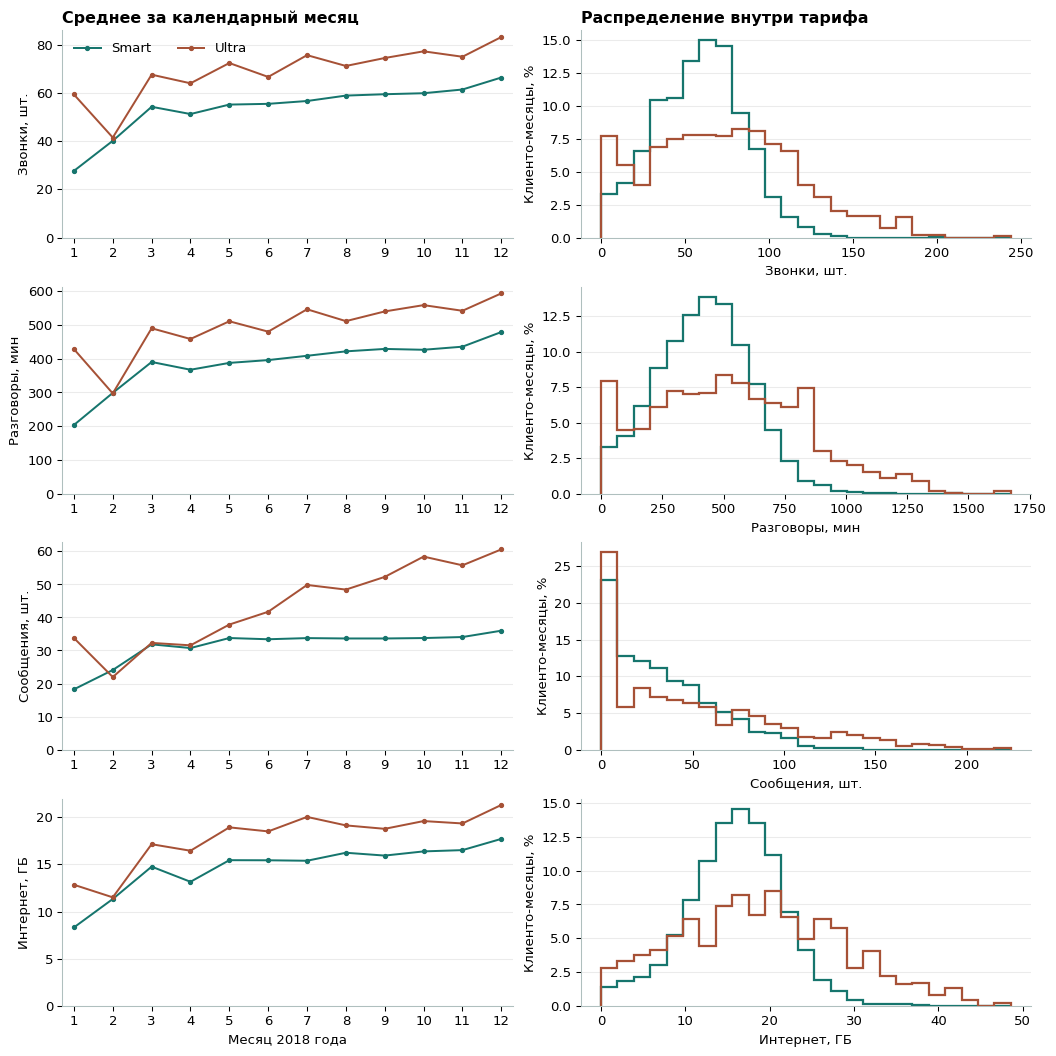

In [33]:
fig, axes = plt.subplots(4, 2, figsize=(11, 11), layout='constrained')
for (field, unit), (trend, hist) in zip(fields.items(), axes):
    bins = np.histogram_bin_edges(user_behavior[field], bins=25)
    for tariff, color in colors.items():
        means = stats_df[(field, 'mean')].xs(tariff, level='tariff')
        trend.plot(means.index, means, marker='o', ms=3, color=color, label=tariff.title())
        values = user_behavior.loc[user_behavior['tariff'].eq(tariff), field]
        hist.hist(values, bins=bins, weights=np.full(len(values), 100 / len(values)),
                  histtype='step', linewidth=1.7, color=color, label=tariff.title())
    trend.set(ylabel=unit, xticks=range(1, 13), xlim=(0.7, 12.3), ylim=(0, None))
    hist.set(xlabel=unit, ylabel='Клиенто-месяцы, %')
    trend.grid(axis='y')
    hist.grid(axis='y')
axes[0, 0].set_title('Среднее за календарный месяц')
axes[0, 1].set_title('Распределение внутри тарифа')
axes[0, 0].legend(frameon=False, ncol=2)
axes[-1, 0].set_xlabel('Месяц 2018 года')
plt.show()

In [34]:
by_plan = user_behavior.groupby('tariff')
consumption = by_plan[list(fields)].mean().rename(columns=fields)
share_above = user_behavior[['tariff', 'paid_minutes', 'paid_messages', 'paid_gb']].copy()
limit_fields = {'paid_minutes': 'Минуты', 'paid_messages': 'Сообщения', 'paid_gb': 'Интернет'}
share_above[list(limit_fields)] = share_above[list(limit_fields)].gt(0)
print('Среднее потребление за месяц')
display(consumption.round(1))
print('Доля месяцев с превышением пакета, %')
display(share_above.groupby('tariff')[list(limit_fields)].mean().mul(100)
        .rename(columns=limit_fields).round(1))

Среднее потребление за месяц


,"Звонки, шт.","Разговоры, мин","Сообщения, шт.","Интернет, ГБ"
tariff,,,,
smart,58.5,417.9,33.4,15.8
ultra,73.4,526.6,49.4,19.0


Доля месяцев с превышением пакета, %


,Минуты,Сообщения,Интернет
tariff,,,
smart,33.8,25.3,58.5
ultra,0.0,0.0,13.6


Клиенты Ultra в среднем использовали больше минут, сообщений и интернета. При этом пакетов минут и сообщений Ultra хватило во всех наблюдаемых месяцах. На Smart чаще всего не хватало интернета — пакет в 15 ГБ был превышен примерно в 59% месяцев. Состав абонентов менялся в течение года, поэтому рост средних на графике сам по себе не доказывает, что каждый клиент стал пользоваться связью активнее.

In [35]:
revenue = by_plan.agg(
    clients=('user_id', 'nunique'), months=('month', 'size'), total=('total_cost', 'sum'),
    mean=('total_cost', 'mean'), median=('total_cost', 'median'), fee=('rub_monthly_fee', 'mean'),
    minutes=('cost_minutes', 'mean'), sms=('cost_messages', 'mean'), internet=('cost_gb', 'mean'),
)
display(revenue.rename(columns={
    'clients':'Абоненты', 'months':'Клиенто-месяцы', 'total':'Сумма, ₽',
    'mean':'Среднее, ₽', 'median':'Медиана, ₽', 'fee':'Абонплата, ₽',
    'minutes':'Доплата за минуты, ₽', 'sms':'Доплата за SMS, ₽', 'internet':'Доплата за ГБ, ₽',
}).round(2))

,Абоненты,Клиенто-месяцы,"Сумма, ₽","Среднее, ₽","Медиана, ₽","Абонплата, ₽","Доплата за минуты, ₽","Доплата за SMS, ₽","Доплата за ГБ, ₽"
tariff,,,,,,,,,
smart,350,2229,2875351,1289.97,1023.0,550.0,124.82,17.4,597.76
ultra,148,985,2039100,2070.15,1950.0,1950.0,0.00,0.0,120.15


У Smart базовая плата 550 ₽, но средний счёт заметно выше из-за доплат, особенно за интернет. У Ultra медианный счёт совпадает с абонентской платой — 1 950 ₽. На Smart приходится больше общей выручки выборки, поскольку у этого тарифа больше абонентов и наблюдаемых месяцев.

## 4. Проверка гипотез

### Задание 28. Различается ли средняя месячная выручка Smart и Ultra?

Нулевая гипотеза — средние начисления по двум тарифам равны. Альтернатива — средние различаются в любую сторону. Как в исходной работе, применяю двусторонний t-тест Уэлча с уровнем значимости 0,05. Уэлч допускает разные дисперсии и размеры выборок. В заданиях 28 и 29 одна строка — месяц одного клиента. Повторные месяцы одного человека могут быть связаны между собой, поэтому в конце проверю вывод на уровне абонентов.

In [36]:
alpha = 0.05
ultra = user_behavior.loc[user_behavior['tariff'].eq('ultra'), 'total_cost']
smart = user_behavior.loc[user_behavior['tariff'].eq('smart'), 'total_cost']
results = st.ttest_ind(ultra, smart, equal_var=False)
print(results.pvalue)
if results.pvalue < alpha:
    print('Отвергаем нулевую гипотезу')
else:
    print('Не получилось отвергнуть нулевую гипотезу')

4.2606313931066694e-250
Отвергаем нулевую гипотезу


Средняя выручка в наблюдаемый месяц выше у Ultra примерно на 780 ₽. При уровне значимости 5% данные дают основания отвергнуть равенство средних.

### Задание 29. Отличается ли средняя выручка в Москве от других регионов?

Нулевая гипотеза — средняя месячная выручка от московских абонентов и от абонентов остальных городов одинакова. Альтернатива — она различается. Воспроизвожу двусторонний t-тест Стьюдента для независимых выборок из исходного решения. В этом варианте предполагаются равные дисперсии. В дополнительной проверке ниже это предположение снято.

In [37]:
msk = user_behavior.loc[user_behavior['city'].eq('Москва'), 'total_cost']
other_city = user_behavior.loc[user_behavior['city'].ne('Москва'), 'total_cost']
results = st.ttest_ind(msk, other_city, equal_var=True)
print(results.pvalue)
if results.pvalue < alpha:
    print('Отвергаем нулевую гипотезу')
else:
    print('Не получилось отвергнуть нулевую гипотезу')

0.5440152911670225
Не получилось отвергнуть нулевую гипотезу


При пороге 5% статистически значимого различия по регионам не обнаружено. Данных недостаточно, чтобы утверждать, что средняя выручка Москвы выше или ниже.

### Проверка вывода по абонентам

Абонент, который наблюдался двенадцать месяцев, в основных тестах получает больший вес, чем подключившийся в декабре. Усредню начисления за наблюдаемые месяцы каждого человека и применю тест Уэлча к полученным средним. В таком расчёте каждый абонент имеет одинаковый вес.

In [38]:
per_client = (user_behavior.groupby(['user_id', 'tariff', 'city'], as_index=False)
              .agg(mean_bill=('total_cost', 'mean')))
comparisons = {
    'Ultra / Smart': per_client['tariff'].eq('ultra'),
    'Москва / остальные города': per_client['city'].eq('Москва'),
}
sensitivity = []
for label, first_group in comparisons.items():
    first = per_client.loc[first_group, 'mean_bill']
    second = per_client.loc[~first_group, 'mean_bill']
    test = st.ttest_ind(first, second, equal_var=False)
    sensitivity.append([label, len(first), len(second), round(first.mean(), 2),
                        round(second.mean(), 2), f'{test.pvalue:.3g}'])
display(pd.DataFrame(sensitivity, columns=[
    'Сравнение', 'Абонентов в 1-й', 'Абонентов во 2-й',
    'Среднее в 1-й, ₽', 'Среднее во 2-й, ₽', 'p-value',
]).set_index('Сравнение'))

,Абонентов в 1-й,Абонентов во 2-й,"Среднее в 1-й, ₽","Среднее во 2-й, ₽",p-value
Сравнение,,,,,
Ultra / Smart,148,350,2086.46,1324.40,2.08e-59
Москва / остальные города,99,399,1498.47,1563.88,0.344


При равном весе абонентов месячная выручка Ultra всё ещё больше примерно на 762 ₽. В сравнении регионов меняется даже знак разницы, но при обоих способах взвешивания она статистически незначима.

### Два месяца без событий

Плата по договору может начисляться и при нулевом потреблении. Для проверки посчитаю месяцы от подключения до отключения включительно, а для действующих договоров — до декабря 2018 года. Посмотрю, как изменится средний счёт, если за каждый месяц без событий начислить полную абонплату. Выставленных оператором счетов в данных нет.

In [39]:
end_month = users['churn_date'].fillna(pd.Timestamp('2018-12-31')).dt.month
contract_months = pd.DataFrame({
    'tariff': users['tariff'], 'months': end_month - users['reg_date'].dt.month + 1,
}).groupby('tariff')['months'].sum()
fees = tariffs.set_index('tariff_name')['rub_monthly_fee']
coverage = revenue[['months', 'total']].copy()
coverage['silent'] = contract_months - coverage['months']
coverage['incl_fee'] = coverage['total'] + coverage['silent'] * fees
coverage['mean_incl_fee'] = coverage['incl_fee'] / contract_months
display(coverage[['silent', 'incl_fee', 'mean_incl_fee']].rename(columns={
    'silent':'Месяцев договора без событий', 'incl_fee':'Выручка с их учётом, ₽',
    'mean_incl_fee':'Среднее за месяц договора, ₽',
}).round(2))

,Месяцев договора без событий,"Выручка с их учётом, ₽","Среднее за месяц договора, ₽"
tariff,,,
smart,1,2875901,1289.64
ultra,1,2041050,2070.03


В журнале отсутствует по одному месяцу каждого тарифа. Даже при полной абонплате за оба месяца итог практически тот же — 2 070,03 ₽ на Ultra и 1 289,64 ₽ на Smart.

## Вывод для коммерческого отдела

Если цель кампании — высокая месячная выручка с одного подключившегося абонента, по этой выборке я бы в первую очередь проверил рекламу **Ultra**. Здесь месяц приносил в среднем 2 070 ₽, на Smart — 1 290 ₽. Вывод о различии сохранился, когда я дал каждому абоненту одинаковый вес. По Москве и другим городам убедительного различия не обнаружил ни в одном варианте расчёта.

**Smart** принёс больше денег в сумме. Значительную часть его выручки составляют доплаты, прежде всего за интернет. В рекламе такого тарифа я бы проверил, насколько ожидания клиента от пакета в 15 ГБ совпадают с его расходом.

Выборка описывает действующих клиентов за 2018 год. Для решения о бюджете я бы сравнил стоимость привлечения, конверсию в подключение, удержание и затраты на обслуживание. По сумме начислений нельзя определить прибыль с рекламного рубля.